## 1. Load the Extracted Feature Dataset

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Define the project paths
project_folder = Path(
    r"C:\Users\harsh\Downloads\Digital_Twin_Project"
)

features_folder = project_folder / "data" / "processed"

print("Project folder exists:", project_folder.exists())
print("Processed data folder exists:", features_folder.exists())

if features_folder.exists():
    for file in features_folder.iterdir():
        print(file.name)

Project folder exists: True
Processed data folder exists: True
ims_anomaly_results.csv
ims_bearing_features.csv


## 2. Load and Inspect the Bearing Feature Dataset

In [2]:
# Load the extracted bearing features
features_path = (
    project_folder
    / "data"
    / "processed"
    / "ims_bearing_features.csv"
)

features_df = pd.read_csv(features_path)

# Inspect the dataset
print("Dataset shape:", features_df.shape)

print("\nColumn names:")
print(features_df.columns.tolist())

print("\nFirst five rows:")
display(features_df.head())

print("\nMissing values:", features_df.isnull().sum().sum())

print("\nDuplicate rows:", features_df.duplicated().sum())

Dataset shape: (2156, 33)

Column names:
['timestamp', 'ch0_rms', 'ch0_std', 'ch0_peak_to_peak', 'ch0_kurtosis', 'ch1_rms', 'ch1_std', 'ch1_peak_to_peak', 'ch1_kurtosis', 'ch2_rms', 'ch2_std', 'ch2_peak_to_peak', 'ch2_kurtosis', 'ch3_rms', 'ch3_std', 'ch3_peak_to_peak', 'ch3_kurtosis', 'ch4_rms', 'ch4_std', 'ch4_peak_to_peak', 'ch4_kurtosis', 'ch5_rms', 'ch5_std', 'ch5_peak_to_peak', 'ch5_kurtosis', 'ch6_rms', 'ch6_std', 'ch6_peak_to_peak', 'ch6_kurtosis', 'ch7_rms', 'ch7_std', 'ch7_peak_to_peak', 'ch7_kurtosis']

First five rows:


,timestamp,ch0_rms,ch0_std,ch0_peak_to_peak,ch0_kurtosis,ch1_rms,ch1_std,ch1_peak_to_peak,ch1_kurtosis,ch2_rms,...,ch5_peak_to_peak,ch5_kurtosis,ch6_rms,ch6_std,ch6_peak_to_peak,ch6_kurtosis,ch7_rms,ch7_std,ch7_peak_to_peak,ch7_kurtosis
0,2003-10-22 12:06:24,0.124614,0.081124,1.108,1.069717,0.117493,0.070650,1.265,3.066925,0.130455,...,1.199,0.777546,0.109020,0.060086,0.662,0.790736,0.115267,0.066382,0.845,1.808725
1,2003-10-22 12:09:13,0.123811,0.079517,1.042,1.162128,0.116833,0.069531,1.072,2.001798,0.131490,...,0.993,0.682736,0.108900,0.059421,0.796,1.235297,0.109208,0.064746,0.900,1.873939
2,2003-10-22 12:14:13,0.125246,0.080219,0.940,0.986819,0.118384,0.069465,1.018,1.969725,0.131906,...,0.984,0.750898,0.110319,0.059969,0.657,0.925227,0.113696,0.065255,0.977,1.430337
3,2003-10-22 12:19:13,0.125197,0.080827,1.055,1.034839,0.119005,0.071267,1.009,1.746089,0.131614,...,1.036,0.667669,0.111037,0.059917,0.591,0.653119,0.114413,0.066303,0.852,1.378814
4,2003-10-22 12:24:13,0.125618,0.082036,1.011,1.110728,0.119688,0.072155,0.923,1.181742,0.130779,...,1.055,0.475712,0.110190,0.059257,0.591,0.636024,0.114258,0.066280,0.871,1.498312



Missing values: 0

Duplicate rows: 0


## 3. Data Quality and Timestamp Validation

In [3]:
# Convert timestamps to datetime
features_df["timestamp"] = pd.to_datetime(
    features_df["timestamp"],
    errors="coerce"
)

# Separate timestamp and vibration features
feature_columns = [
    column for column in features_df.columns
    if column != "timestamp"
]

# Check data quality
print("Number of recordings:", len(features_df))
print("Number of vibration features:", len(feature_columns))

print("\nInvalid timestamps:",
      features_df["timestamp"].isna().sum())

print("Duplicate timestamps:",
      features_df["timestamp"].duplicated().sum())

print("Missing feature values:",
      features_df[feature_columns].isna().sum().sum())

print("Infinite feature values:",
      np.isinf(features_df[feature_columns].to_numpy()).sum())

print("Timestamps already sorted:",
      features_df["timestamp"].is_monotonic_increasing)

print("\nRecording period:")
print("Start:", features_df["timestamp"].min())
print("End:  ", features_df["timestamp"].max())

print("\nFeature summary:")
display(features_df[feature_columns].describe().round(4))


Number of recordings: 2156
Number of vibration features: 32

Invalid timestamps: 0
Duplicate timestamps: 0
Missing feature values: 0
Infinite feature values: 0
Timestamps already sorted: True

Recording period:
Start: 2003-10-22 12:06:24
End:   2003-11-25 23:39:56

Feature summary:


,ch0_rms,ch0_std,ch0_peak_to_peak,ch0_kurtosis,ch1_rms,ch1_std,ch1_peak_to_peak,ch1_kurtosis,ch2_rms,ch2_std,...,ch5_peak_to_peak,ch5_kurtosis,ch6_rms,ch6_std,ch6_peak_to_peak,ch6_kurtosis,ch7_rms,ch7_std,ch7_peak_to_peak,ch7_kurtosis
count,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,...,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000,2156.0000
mean,0.1522,0.0986,1.1780,0.9986,0.1460,0.0890,1.1627,1.1043,0.1495,0.0944,...,1.4162,0.8372,0.1468,0.0917,1.2229,2.1019,0.1486,0.0953,1.3145,2.1646
std,0.0072,0.0053,0.1076,0.1974,0.0074,0.0053,0.1320,0.3082,0.0067,0.0064,...,0.6263,1.2455,0.0215,0.0284,0.7502,3.4539,0.0200,0.0254,0.7136,3.3462
min,0.1238,0.0794,0.8220,0.2800,0.1168,0.0693,0.8250,0.2661,0.1294,0.0882,...,0.8160,0.2250,0.0622,0.0582,0.5590,0.4254,0.0885,0.0642,0.6810,0.4824
25%,0.1522,0.0970,1.1040,0.8684,0.1464,0.0879,1.0700,0.8921,0.1487,0.0917,...,1.1430,0.4537,0.1356,0.0732,0.7910,0.8886,0.1387,0.0791,0.9220,1.0457
50%,0.1537,0.0991,1.1755,0.9964,0.1480,0.0902,1.1500,1.0677,0.1498,0.0931,...,1.2280,0.5329,0.1390,0.0791,0.9200,1.2520,0.1412,0.0830,1.0620,1.3474
75%,0.1553,0.1012,1.2500,1.1244,0.1491,0.0918,1.2480,1.2740,0.1512,0.0950,...,1.3752,0.6473,0.1564,0.1035,1.4430,1.7735,0.1599,0.1091,1.4302,1.8893
max,0.1750,0.1297,1.5330,1.7002,0.1595,0.1070,1.7670,3.0669,0.2119,0.1762,...,8.9920,15.8882,0.2373,0.2044,7.3470,71.5720,0.2345,0.1811,7.1220,56.3812


## 4. Checking Time Gaps Between Recordings

In [4]:
# Calculate the time difference between consecutive recordings
time_gaps = features_df["timestamp"].diff()

print("Most common recording intervals:")
display(time_gaps.value_counts().head(10).rename_axis("Time gap").to_frame("Count"))

print("\nMedian recording interval:", time_gaps.median())
print("Mean recording interval:", time_gaps.mean())
print("Intervals longer than 30 minutes:", (time_gaps > pd.Timedelta(minutes=30)).sum())
print("Longest recording gap:", time_gaps.max())

Most common recording intervals:


,Count
Time gap,
0 days 00:10:00,1962
0 days 00:05:00,145
0 days 00:02:49,1
0 days 00:08:35,1
0 days 00:06:25,1
0 days 00:05:25,1
0 days 00:04:35,1
6 days 04:25:33,1
0 days 20:30:00,1



Median recording interval: 0 days 00:10:00
Mean recording interval: 0 days 00:23:02.464965
Intervals longer than 30 minutes: 24
Longest recording gap: 6 days 04:25:33


## 5. Exploring Vibration Trends Over Time

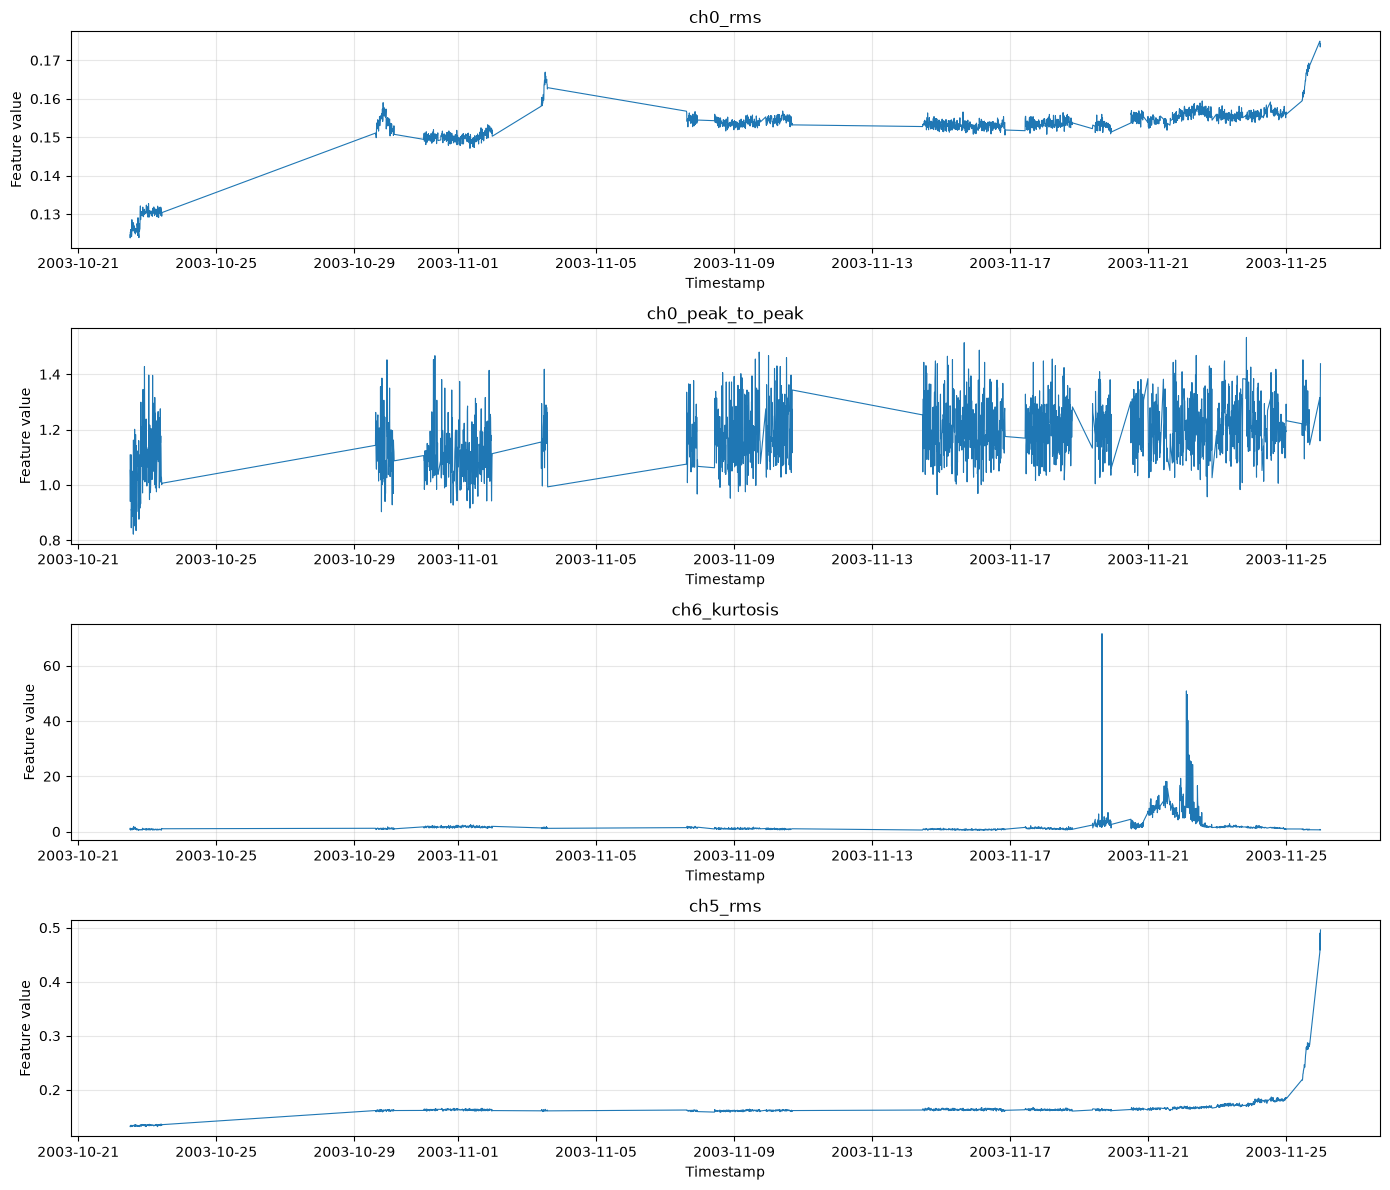

In [5]:
# Select a few features to inspect
features_to_plot = [
    "ch0_rms",
    "ch0_peak_to_peak",
    "ch6_kurtosis",
    "ch5_rms"
]

fig, axes = plt.subplots(
    nrows=len(features_to_plot),
    ncols=1,
    figsize=(14, 12)
)

for ax, feature in zip(axes, features_to_plot):
    ax.plot(
        features_df["timestamp"],
        features_df[feature],
        linewidth=0.8
    )

    ax.set_title(feature)
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Feature value")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# Features selected for trend analysis
features_to_plot = [
    "ch0_rms",
    "ch0_peak_to_peak",
    "ch6_kurtosis",
    "ch5_rms"
]

for feature in features_to_plot:
    values = features_df[feature]

    print("\n" + "=" * 55)
    print(f"Feature: {feature}")
    print("=" * 55)

    print("Minimum:", round(values.min(), 4))
    print("25th percentile:", round(values.quantile(0.25), 4))
    print("Median:", round(values.median(), 4))
    print("75th percentile:", round(values.quantile(0.75), 4))
    print("95th percentile:", round(values.quantile(0.95), 4))
    print("99th percentile:", round(values.quantile(0.99), 4))
    print("Maximum:", round(values.max(), 4))

    print(
        "First recorded value:",
        round(values.iloc[0], 4),
        "|",
        features_df["timestamp"].iloc[0]
    )

    print(
        "Last recorded value:",
        round(values.iloc[-1], 4),
        "|",
        features_df["timestamp"].iloc[-1]
    )

    print(
        "First 10% median:",
        round(values.iloc[:int(len(values) * 0.1)].median(), 4)
    )

    print(
        "Last 10% median:",
        round(values.iloc[int(len(values) * 0.9):].median(), 4)
    )


Feature: ch0_rms
Minimum: 0.1238
25th percentile: 0.1522
Median: 0.1537
75th percentile: 0.1553
95th percentile: 0.1575
99th percentile: 0.166
Maximum: 0.175
First recorded value: 0.1246 | 2003-10-22 12:06:24
Last recorded value: 0.1742 | 2003-11-25 23:39:56
First 10% median: 0.1305
Last 10% median: 0.1562

Feature: ch0_peak_to_peak
Minimum: 0.822
25th percentile: 1.104
Median: 1.1755
75th percentile: 1.25
95th percentile: 1.3625
99th percentile: 1.443
Maximum: 1.533
First recorded value: 1.108 | 2003-10-22 12:06:24
Last recorded value: 1.438 | 2003-11-25 23:39:56
First 10% median: 1.084
Last 10% median: 1.2125

Feature: ch6_kurtosis
Minimum: 0.4254
25th percentile: 0.8886
Median: 1.252
75th percentile: 1.7735
95th percentile: 7.9163
99th percentile: 15.6418
Maximum: 71.572
First recorded value: 0.7907 | 2003-10-22 12:06:24
Last recorded value: 0.6265 | 2003-11-25 23:39:56
First 10% median: 0.8547
Last 10% median: 1.3627

Feature: ch5_rms
Minimum: 0.1317
25th percentile: 0.1617
Median

## 6. Preparing the Dataset for Anomaly Detection

In [7]:
# Sort recordings chronologically
features_df = (
    features_df
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Identify vibration features (exclude timestamp)
feature_columns = [
    column for column in features_df.columns
    if column != "timestamp"
]

# Separate the features from the timestamps
X = features_df[feature_columns].copy()
timestamps = features_df["timestamp"].copy()

# Use the first 70% for training
split_index = int(len(features_df) * 0.70)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

timestamps_train = timestamps.iloc[:split_index]
timestamps_test = timestamps.iloc[split_index:]

print("Total recordings:", len(features_df))
print("Number of features:", len(feature_columns))

print("\nTraining recordings:", len(X_train))
print("Testing recordings:", len(X_test))

print("\nTraining period:")
print(timestamps_train.iloc[0], "to", timestamps_train.iloc[-1])

print("\nTesting period:")
print(timestamps_test.iloc[0], "to", timestamps_test.iloc[-1])

print("\nMissing training values:", X_train.isna().sum().sum())
print("Missing testing values:", X_test.isna().sum().sum())

Total recordings: 2156
Number of features: 32

Training recordings: 1509
Testing recordings: 647

Training period:
2003-10-22 12:06:24 to 2003-11-20 11:54:03

Testing period:
2003-11-20 11:59:03 to 2003-11-25 23:39:56

Missing training values: 0
Missing testing values: 0


## 7. Training the Isolation Forest Anomaly Detection Model

In [8]:
from sklearn.ensemble import IsolationForest

# Create the anomaly detection model
isolation_model = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42
)

# Train using only the training period
isolation_model.fit(X_train)

print("Isolation Forest training completed successfully.")
print("Number of training recordings:", len(X_train))
print("Number of features:", X_train.shape[1])
print("Number of trees:", isolation_model.n_estimators)
print("Configured training contamination:", isolation_model.contamination)

Isolation Forest training completed successfully.
Number of training recordings: 1509
Number of features: 32
Number of trees: 200
Configured training contamination: 0.02


## 8. Detecting Anomalies in Training and Testing Data

In [9]:
# Predict anomaly labels
#  1 = normal observation
# -1 = potential anomaly
train_predictions = isolation_model.predict(X_train)
test_predictions = isolation_model.predict(X_test)

# Calculate anomaly scores
# Negative decision_function scores indicate potential anomalies
train_scores = isolation_model.decision_function(X_train)
test_scores = isolation_model.decision_function(X_test)

# Count potential anomalies
train_anomalies = (train_predictions == -1).sum()
test_anomalies = (test_predictions == -1).sum()

print("TRAINING RESULTS")
print("-" * 40)
print("Total recordings:", len(X_train))
print("Potential anomalies:", train_anomalies)
print("Anomaly percentage:", round(train_anomalies / len(X_train) * 100, 2), "%")
print("Minimum decision score:", round(train_scores.min(), 4))
print("Maximum decision score:", round(train_scores.max(), 4))

print("\nTESTING RESULTS")
print("-" * 40)
print("Total recordings:", len(X_test))
print("Potential anomalies:", test_anomalies)
print("Anomaly percentage:", round(test_anomalies / len(X_test) * 100, 2), "%")
print("Minimum decision score:", round(test_scores.min(), 4))
print("Maximum decision score:", round(test_scores.max(), 4))

TRAINING RESULTS
----------------------------------------
Total recordings: 1509
Potential anomalies: 31
Anomaly percentage: 2.05 %
Minimum decision score: -0.0415
Maximum decision score: 0.2146

TESTING RESULTS
----------------------------------------
Total recordings: 647
Potential anomalies: 496
Anomaly percentage: 76.66 %
Minimum decision score: -0.1395
Maximum decision score: 0.1293


## 10. Daily Anomaly Rate Analysis

In [10]:
# Combine test timestamps, predictions, and scores
test_results = pd.DataFrame({
    "timestamp": timestamps_test.to_numpy(),
    "prediction": test_predictions,
    "anomaly_score": test_scores
})

# Mark potential anomalies
test_results["is_anomaly"] = (
    test_results["prediction"] == -1
)

# Group recordings by calendar day
daily_anomaly_summary = (
    test_results
    .assign(date=test_results["timestamp"].dt.date)
    .groupby("date")
    .agg(
        total_recordings=("is_anomaly", "size"),
        potential_anomalies=("is_anomaly", "sum"),
        mean_anomaly_score=("anomaly_score", "mean")
    )
)

daily_anomaly_summary["anomaly_percentage"] = (
    daily_anomaly_summary["potential_anomalies"]
    / daily_anomaly_summary["total_recordings"]
    * 100
)

display(daily_anomaly_summary.round(3))

,total_recordings,potential_anomalies,mean_anomaly_score,anomaly_percentage
date,,,,
2003-11-20,108,0,0.084,0.000
2003-11-21,117,81,-0.011,69.231
2003-11-22,128,127,-0.051,99.219
2003-11-23,131,125,-0.050,95.420
2003-11-24,126,126,-0.059,100.000
2003-11-25,37,37,-0.109,100.000


## 11. Comparing Training and Testing Feature Distributions

In [11]:
# Compare the median of every feature between the two periods
feature_comparison = pd.DataFrame({
    "training_median": X_train.median(),
    "testing_median": X_test.median()
})

feature_comparison["absolute_change"] = (
    feature_comparison["testing_median"]
    - feature_comparison["training_median"]
).abs()

# Percentage change relative to the training median
feature_comparison["percentage_change"] = (
    (
        feature_comparison["testing_median"]
        - feature_comparison["training_median"]
    )
    / X_train.median().abs().replace(0, np.nan)
) * 100

# Show features with the largest absolute median changes
feature_comparison = feature_comparison.sort_values(
    "percentage_change",
    key=lambda column: column.abs(),
    ascending=False
)

display(feature_comparison.head(12).round(4))

,training_median,testing_median,absolute_change,percentage_change
ch4_kurtosis,0.5489,1.1456,0.5967,108.6964
ch6_peak_to_peak,0.8400,1.6260,0.7860,93.5714
ch6_kurtosis,1.0432,1.8645,0.8213,78.7239
ch6_std,0.0744,0.1325,0.0582,78.2188
ch7_peak_to_peak,0.9740,1.7190,0.7450,76.4887
ch7_std,0.0802,0.1354,0.0551,68.7119
ch4_peak_to_peak,1.2230,1.8100,0.5870,47.9967
ch7_kurtosis,1.2292,1.7826,0.5534,45.0212
ch6_rms,0.1364,0.1753,0.0389,28.5092
ch7_rms,0.1396,0.1772,0.0376,26.9393


## 12. Tracking the Most Changed Features Over Time

In [12]:
# Select features with large changes between training and testing
features_to_inspect = [
    "ch4_kurtosis",
    "ch6_peak_to_peak",
    "ch6_kurtosis",
    "ch6_std",
    "ch7_peak_to_peak",
    "ch7_std"
]

# Split the full dataset into chronological periods of equal row count
number_of_periods = 10
period_labels = np.array_split(
    np.arange(len(features_df)),
    number_of_periods
)

period_summary = []

for period_number, row_indices in enumerate(period_labels, start=1):
    period_data = features_df.iloc[row_indices]

    row = {
        "period": period_number,
        "start": period_data["timestamp"].iloc[0],
        "end": period_data["timestamp"].iloc[-1]
    }

    for feature in features_to_inspect:
        row[feature] = period_data[feature].median()

    period_summary.append(row)

period_summary_df = pd.DataFrame(period_summary)

display(period_summary_df.round(4))

C:\Users\harsh\AppData\Local\Temp\ipykernel_26236\2206651952.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(period_summary_df.round(4))


,period,start,end,ch4_kurtosis,ch6_peak_to_peak,ch6_kurtosis,ch6_std,ch7_peak_to_peak,ch7_std
0,1,2003-10-22 12:06:24,2003-10-30 00:29:46,0.3663,0.7180,0.8552,0.0640,0.8715,0.0692
1,2,2003-10-30 00:39:46,2003-11-01 10:31:44,0.4242,0.9420,1.6941,0.0787,1.0815,0.0830
2,3,2003-11-01 10:41:44,2003-11-08 20:11:44,0.4771,0.8800,1.4338,0.0756,1.0585,0.0830
3,4,2003-11-08 20:21:44,2003-11-10 11:35:58,0.5467,0.7850,1.0239,0.0727,0.9375,0.0797
4,5,2003-11-10 11:45:58,2003-11-15 18:28:46,0.7536,0.7775,0.7879,0.0732,0.8940,0.0784
5,6,2003-11-15 18:38:46,2003-11-17 20:02:30,0.7525,0.8230,0.8097,0.0742,0.9240,0.0792
6,7,2003-11-17 20:12:30,2003-11-20 12:04:03,0.7038,1.0380,1.1997,0.0841,1.0350,0.0847
7,8,2003-11-20 12:09:03,2003-11-21 22:36:56,0.7356,2.0110,5.1335,0.1047,1.9940,0.1094
8,9,2003-11-21 22:46:56,2003-11-23 13:06:56,1.4994,1.8430,2.0240,0.1460,2.1220,0.1414
9,10,2003-11-23 13:16:56,2003-11-25 23:39:56,4.2955,1.4430,1.3534,0.1305,1.5650,0.1356


## 13. Investigating Extreme Vibration Recordings

In [13]:
# Inspect the 10 highest ch6_kurtosis readings
print("TOP 10 RECORDINGS BY ch6_kurtosis")
display(
    features_df.nlargest(10, "ch6_kurtosis")[
        ["timestamp", "ch6_kurtosis", "ch6_peak_to_peak", "ch6_std"]
    ].reset_index(drop=True).round(4)
)

# Inspect the 10 highest ch5_rms readings
print("\nTOP 10 RECORDINGS BY ch5_rms")
display(
    features_df.nlargest(10, "ch5_rms")[
        ["timestamp", "ch5_rms", "ch5_peak_to_peak", "ch5_kurtosis"]
    ].reset_index(drop=True).round(4)
)

TOP 10 RECORDINGS BY ch6_kurtosis


C:\Users\harsh\AppData\Local\Temp\ipykernel_26236\2035846919.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].reset_index(drop=True).round(4)


,timestamp,ch6_kurtosis,ch6_peak_to_peak,ch6_std
0,2003-11-19 15:46:07,71.5720,4.008,0.0863
1,2003-11-22 02:26:56,50.8644,7.347,0.1766
2,2003-11-22 03:06:56,49.5378,7.256,0.1827
3,2003-11-22 03:26:56,40.2264,6.392,0.1776
4,2003-11-22 04:16:56,27.7040,6.147,0.1647
5,2003-11-22 05:06:56,25.5675,6.077,0.1539
6,2003-11-22 05:46:56,25.2914,6.460,0.1727
7,2003-11-22 06:46:56,24.2781,5.837,0.1745
8,2003-11-21 22:26:56,19.2522,4.895,0.1526
9,2003-11-21 12:48:36,18.1405,4.392,0.1399



TOP 10 RECORDINGS BY ch5_rms


C:\Users\harsh\AppData\Local\Temp\ipykernel_26236\2035846919.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].reset_index(drop=True).round(4)


,timestamp,ch5_rms,ch5_peak_to_peak,ch5_kurtosis
0,2003-11-25 23:39:56,0.4960,7.349,4.2671
1,2003-11-25 23:19:56,0.4903,8.992,6.7555
2,2003-11-25 23:29:56,0.4589,7.568,5.8171
3,2003-11-25 23:13:21,0.4550,8.884,6.8124
4,2003-11-25 14:37:32,0.2871,4.536,3.1783
5,2003-11-25 14:47:32,0.2865,3.875,2.9084
6,2003-11-25 15:37:32,0.2862,3.423,2.4672
7,2003-11-25 15:57:32,0.2830,3.281,1.9002
8,2003-11-25 16:07:32,0.2830,3.503,2.3064
9,2003-11-25 15:17:32,0.2830,3.626,2.4586


## 14. Comparing Extreme Readings with Model Anomaly Flags

In [14]:
# Combine timestamps, model predictions, and anomaly scores
all_results = pd.DataFrame({
    "timestamp": timestamps.to_numpy(),
    "prediction": isolation_model.predict(X),
    "anomaly_score": isolation_model.decision_function(X)
})

all_results["is_anomaly"] = all_results["prediction"] == -1

# Identify the 10 highest ch6_kurtosis readings
extreme_kurtosis = features_df.nlargest(
    10, "ch6_kurtosis"
)[["timestamp", "ch6_kurtosis", "ch6_peak_to_peak", "ch6_std"]]

# Match these recordings with the model's decisions
extreme_results = extreme_kurtosis.merge(
    all_results,
    on="timestamp",
    how="left"
)

display(
    extreme_results[
        [
            "timestamp",
            "ch6_kurtosis",
            "ch6_peak_to_peak",
            "ch6_std",
            "anomaly_score",
            "is_anomaly"
        ]
    ].round(4)
)

C:\Users\harsh\AppData\Local\Temp\ipykernel_26236\552685954.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,timestamp,ch6_kurtosis,ch6_peak_to_peak,ch6_std,anomaly_score,is_anomaly
0,2003-11-19 15:46:07,71.5720,4.008,0.0863,0.0227,False
1,2003-11-22 02:26:56,50.8644,7.347,0.1766,-0.0548,True
2,2003-11-22 03:06:56,49.5378,7.256,0.1827,-0.0715,True
3,2003-11-22 03:26:56,40.2264,6.392,0.1776,-0.0940,True
4,2003-11-22 04:16:56,27.7040,6.147,0.1647,-0.0690,True
5,2003-11-22 05:06:56,25.5675,6.077,0.1539,-0.0371,True
6,2003-11-22 05:46:56,25.2914,6.460,0.1727,-0.0548,True
7,2003-11-22 06:46:56,24.2781,5.837,0.1745,-0.0455,True
8,2003-11-21 22:26:56,19.2522,4.895,0.1526,-0.0431,True
9,2003-11-21 12:48:36,18.1405,4.392,0.1399,-0.0566,True


## 15. Comparing the Highest-Kurtosis Recording with Training Data

In [15]:
# Locate the recording with the highest ch6_kurtosis
extreme_index = features_df["ch6_kurtosis"].idxmax()
extreme_record = features_df.loc[extreme_index, feature_columns]

# Compare this recording with the training distribution
comparison = pd.DataFrame({
    "extreme_recording": extreme_record,
    "training_median": X_train.median(),
    "training_95th_percentile": X_train.quantile(0.95),
    "training_99th_percentile": X_train.quantile(0.99)
})

comparison["above_training_99th_percentile"] = (
    comparison["extreme_recording"]
    > comparison["training_99th_percentile"]
)

print("Extreme recording timestamp:")
print(features_df.loc[extreme_index, "timestamp"])

print("\nModel decision score:")
print(round(
    isolation_model.decision_function(
        features_df.loc[[extreme_index], feature_columns]
    )[0],
    4
))

print("\nFeature comparison:")
display(comparison.round(4))

print(
    "\nFeatures above their training 99th percentile:",
    int(comparison["above_training_99th_percentile"].sum()),
    "out of",
    len(feature_columns)
)

Extreme recording timestamp:
2003-11-19 15:46:07

Model decision score:
0.0227

Feature comparison:


,extreme_recording,training_median,training_95th_percentile,training_99th_percentile,above_training_99th_percentile
ch0_rms,0.1529,0.1530,0.1557,0.1624,False
ch0_std,0.0979,0.0979,0.1018,0.1122,False
ch0_peak_to_peak,1.1670,1.1590,1.3586,1.4430,False
ch0_kurtosis,0.9856,1.0027,1.3437,1.5115,False
ch1_rms,0.1477,0.1472,0.1501,0.1549,False
ch1_std,0.0906,0.0889,0.0936,0.1024,False
ch1_peak_to_peak,1.2500,1.1450,1.4040,1.5108,False
ch1_kurtosis,1.7199,1.1095,1.6873,2.0025,False
ch2_rms,0.1487,0.1492,0.1512,0.1519,False
ch2_std,0.0918,0.0924,0.0951,0.0959,False



Features above their training 99th percentile: 5 out of 32


## 16. Comparing Isolation Forest with a Percentile-Based Baseline

In [16]:
# Establish feature-specific thresholds from training data only
percentile_thresholds = X_train.quantile(0.99)

# Flag a recording if any feature exceeds its training 99th percentile
train_percentile_flags = (
    X_train.gt(percentile_thresholds, axis="columns").any(axis=1)
)

test_percentile_flags = (
    X_test.gt(percentile_thresholds, axis="columns").any(axis=1)
)

# Compare the two methods
comparison_results = pd.DataFrame({
    "Method": [
        "Isolation Forest",
        "99th-percentile baseline"
    ],
    "Training anomalies": [
        int((train_predictions == -1).sum()),
        int(train_percentile_flags.sum())
    ],
    "Training anomaly percentage": [
        round((train_predictions == -1).mean() * 100, 2),
        round(train_percentile_flags.mean() * 100, 2)
    ],
    "Testing anomalies": [
        int((test_predictions == -1).sum()),
        int(test_percentile_flags.sum())
    ],
    "Testing anomaly percentage": [
        round((test_predictions == -1).mean() * 100, 2),
        round(test_percentile_flags.mean() * 100, 2)
    ]
})

display(comparison_results)

,Method,Training anomalies,Training anomaly percentage,Testing anomalies,Testing anomaly percentage
0,Isolation Forest,31,2.05,496,76.66
1,99th-percentile baseline,288,19.09,647,100.00


## 17. Agreement Between Anomaly Detection Methods

In [17]:
# Create test-period flags for both methods
test_isolation_flags = test_predictions == -1
test_percentile_flags = test_percentile_flags.to_numpy()

# Count agreement and disagreement
both_flagged = (
    test_isolation_flags & test_percentile_flags
).sum()

isolation_only = (
    test_isolation_flags & ~test_percentile_flags
).sum()

percentile_only = (
    ~test_isolation_flags & test_percentile_flags
).sum()

neither_flagged = (
    ~test_isolation_flags & ~test_percentile_flags
).sum()

agreement_table = pd.DataFrame({
    "Comparison": [
        "Both methods flag anomaly",
        "Isolation Forest only",
        "Percentile baseline only",
        "Neither method flags anomaly"
    ],
    "Recordings": [
        int(both_flagged),
        int(isolation_only),
        int(percentile_only),
        int(neither_flagged)
    ]
})

display(agreement_table)

print(
    "\nOverall agreement:",
    round(
        (
            (test_isolation_flags == test_percentile_flags).mean()
            * 100
        ),
        2
    ),
    "%"
)

,Comparison,Recordings
0,Both methods flag anomaly,496
1,Isolation Forest only,0
2,Percentile baseline only,151
3,Neither method flags anomaly,0



Overall agreement: 76.66 %


## 18. Investigating Disagreements Between Anomaly Detection Methods

In [18]:
# Identify test recordings flagged only by the percentile baseline
disagreement_mask = (
    ~test_isolation_flags & test_percentile_flags
)

disagreement_results = pd.DataFrame({
    "timestamp": timestamps_test.to_numpy(),
    "isolation_forest_score": test_scores,
    "isolation_forest_anomaly": test_isolation_flags,
    "percentile_anomaly": test_percentile_flags
})

disagreement_results = disagreement_results.loc[
    disagreement_mask
].copy()

print("Recordings flagged only by percentile baseline:",
      len(disagreement_results))

print("\nFirst 10 disagreement records:")
display(disagreement_results.head(10).round(4))

print("\nTime range of these recordings:")
print("First:", disagreement_results["timestamp"].min())
print("Last:", disagreement_results["timestamp"].max())

print("\nIsolation Forest score summary:")
display(
    disagreement_results["isolation_forest_score"]
    .describe()
    .round(4)
)

Recordings flagged only by percentile baseline: 151

First 10 disagreement records:


C:\Users\harsh\AppData\Local\Temp\ipykernel_26236\1623484425.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(disagreement_results.head(10).round(4))


,timestamp,isolation_forest_score,isolation_forest_anomaly,percentile_anomaly
0,2003-11-20 11:59:03,0.1182,False,True
1,2003-11-20 12:04:03,0.0811,False,True
2,2003-11-20 12:09:03,0.0875,False,True
3,2003-11-20 12:14:03,0.0666,False,True
4,2003-11-20 12:19:03,0.0930,False,True
5,2003-11-20 12:24:03,0.0472,False,True
6,2003-11-20 12:29:03,0.0512,False,True
7,2003-11-20 12:34:03,0.0629,False,True
8,2003-11-20 12:39:03,0.0951,False,True
9,2003-11-20 12:44:03,0.1081,False,True



Time range of these recordings:
First: 2003-11-20 11:59:03
Last: 2003-11-23 22:11:24

Isolation Forest score summary:


count    151.0000
mean       0.0641
std        0.0391
min        0.0009
25%        0.0235
50%        0.0775
75%        0.0975
max        0.1293
Name: isolation_forest_score, dtype: float64

## 19. Temporal Distribution of Disagreement Records

In [19]:
# Summarise percentile-only flags by date
disagreement_results["date"] = (
    disagreement_results["timestamp"].dt.date
)

disagreement_by_date = (
    disagreement_results
    .groupby("date")
    .agg(
        disagreement_count=("timestamp", "size"),
        first_recording=("timestamp", "min"),
        last_recording=("timestamp", "max"),
        mean_isolation_score=("isolation_forest_score", "mean")
    )
)

display(disagreement_by_date.round(4))

print(
    "\nTotal disagreement records:",
    disagreement_by_date["disagreement_count"].sum()
)

C:\Users\harsh\AppData\Local\Temp\ipykernel_26236\1729189920.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(disagreement_by_date.round(4))


,disagreement_count,first_recording,last_recording,mean_isolation_score
date,,,,
2003-11-20,108,2003-11-20 11:59:03,2003-11-20 23:54:03,0.0837
2003-11-21,36,2003-11-21 00:04:03,2003-11-21 21:16:56,0.0161
2003-11-22,1,2003-11-22 17:06:56,2003-11-22 17:06:56,0.0091
2003-11-23,6,2003-11-23 11:56:56,2003-11-23 22:11:24,0.0085



Total disagreement records: 151


## 20. Identifying Features Triggering Percentile-Based Flags

In [20]:
# Select the percentile-only disagreement records from November 20
nov20_disagreements = disagreement_results[
    disagreement_results["timestamp"].dt.date
    == pd.Timestamp("2003-11-20").date()
]

# Check which features exceed their training thresholds
nov20_indices = nov20_disagreements.index

# Recreate the test-row mask using the original test index
nov20_timestamps = nov20_disagreements["timestamp"]

nov20_rows = features_df[
    features_df["timestamp"].isin(nov20_timestamps)
]

nov20_exceedances = nov20_rows[feature_columns].gt(
    percentile_thresholds,
    axis="columns"
)

feature_trigger_counts = (
    nov20_exceedances.sum()
    .sort_values(ascending=False)
)

feature_trigger_summary = pd.DataFrame({
    "recordings_exceeding_threshold": feature_trigger_counts,
    "percentage_of_Nov20_disagreements": (
        feature_trigger_counts / len(nov20_rows) * 100
    )
})

display(feature_trigger_summary.head(15).round(2))

,recordings_exceeding_threshold,percentage_of_Nov20_disagreements
ch7_std,108,100.00
ch6_std,92,85.19
ch6_rms,75,69.44
ch6_peak_to_peak,16,14.81
ch7_peak_to_peak,9,8.33
ch4_rms,7,6.48
ch4_kurtosis,7,6.48
ch5_std,6,5.56
ch5_rms,6,5.56
ch4_peak_to_peak,5,4.63


## 21. Comparing Training Thresholds with November 20 Measurements

In [21]:
# Focus on the three most frequently triggered features
key_features = [
    "ch7_std",
    "ch6_std",
    "ch6_rms"
]

threshold_comparison = pd.DataFrame({
    "training_median": X_train[key_features].median(),
    "training_99th_percentile": percentile_thresholds[key_features],
    "nov20_median": nov20_rows[key_features].median(),
    "nov20_minimum": nov20_rows[key_features].min(),
    "nov20_maximum": nov20_rows[key_features].max()
})

threshold_comparison["median_above_threshold_percent"] = (
    (
        threshold_comparison["nov20_median"]
        - threshold_comparison["training_99th_percentile"]
    )
    / threshold_comparison["training_99th_percentile"].abs()
    * 100
)

display(threshold_comparison.round(4))

,training_median,training_99th_percentile,nov20_median,nov20_minimum,nov20_maximum,median_above_threshold_percent
ch7_std,0.0802,0.0913,0.1000,0.0943,0.1144,9.5408
ch6_std,0.0744,0.0885,0.0920,0.0851,0.1078,4.0293
ch6_rms,0.1364,0.1459,0.1472,0.1437,0.1573,0.9008


## 22. Daily Trends in Key Vibration Features

In [22]:
# Build a daily summary of the three key features
daily_feature_summary = (
    features_df.assign(
        date=features_df["timestamp"].dt.date,
        period=np.where(
            features_df["timestamp"] < timestamps_test.iloc[0],
            "Training",
            "Testing"
        )
    )
    .groupby(["date", "period"])
    .agg(
        recordings=("timestamp", "size"),
        ch7_std_median=("ch7_std", "median"),
        ch6_std_median=("ch6_std", "median"),
        ch6_rms_median=("ch6_rms", "median")
    )
    .reset_index()
)

# Show the test-period daily values
test_daily_features = daily_feature_summary[
    daily_feature_summary["period"] == "Testing"
].copy()

display(test_daily_features.round(4))

,date,period,recordings,ch7_std_median,ch6_std_median,ch6_rms_median
17,2003-11-20,Testing,108,0.1000,0.0920,0.1472
19,2003-11-21,Testing,117,0.1231,0.1280,0.1719
20,2003-11-22,Testing,128,0.1462,0.1500,0.1885
21,2003-11-23,Testing,131,0.1381,0.1427,0.1832
22,2003-11-24,Testing,126,0.1346,0.1268,0.1709
23,2003-11-25,Testing,37,0.1497,0.1605,0.1979


## 23. Quantifying Vibration Feature Shifts

In [23]:
# Compare training and testing distributions for key features
key_features = [
    "ch7_std",
    "ch6_std",
    "ch6_rms"
]

shift_summary = pd.DataFrame({
    "training_median": X_train[key_features].median(),
    "testing_median": X_test[key_features].median(),
    "training_99th_percentile": percentile_thresholds[key_features]
})

shift_summary["median_change_percent"] = (
    (
        shift_summary["testing_median"]
        - shift_summary["training_median"]
    )
    / shift_summary["training_median"].abs()
    * 100
)

shift_summary["testing_median_above_training_99th_percentile"] = (
    shift_summary["testing_median"]
    > shift_summary["training_99th_percentile"]
)

display(shift_summary.round(4))

,training_median,testing_median,training_99th_percentile,median_change_percent,testing_median_above_training_99th_percentile
ch7_std,0.0802,0.1354,0.0913,68.7119,True
ch6_std,0.0744,0.1325,0.0885,78.2188,True
ch6_rms,0.1364,0.1753,0.1459,28.5092,True


## 24. Consolidating Anomaly Detection Results

In [24]:
# Combine timestamps, model scores, and anomaly flags
anomaly_results = pd.DataFrame({
    "timestamp": timestamps.to_numpy(),
    "isolation_forest_score": all_results["anomaly_score"].to_numpy(),
    "isolation_forest_anomaly": all_results["is_anomaly"].to_numpy(),
    "percentile_baseline_anomaly": pd.concat(
        [
            train_percentile_flags,
            pd.Series(test_percentile_flags, index=X_test.index)
        ]
    ).sort_index().to_numpy()
})

# Add selected vibration features for interpretation
anomaly_results["ch7_std"] = features_df["ch7_std"].to_numpy()
anomaly_results["ch6_std"] = features_df["ch6_std"].to_numpy()
anomaly_results["ch6_rms"] = features_df["ch6_rms"].to_numpy()

print("Results shape:", anomaly_results.shape)
print("\nColumn names:")
print(anomaly_results.columns.tolist())

print("\nAnomaly counts:")
print(
    anomaly_results[
        [
            "isolation_forest_anomaly",
            "percentile_baseline_anomaly"
        ]
    ].sum()
)

print("\nFirst five rows:")
display(anomaly_results.head().round(4))

Results shape: (2156, 7)

Column names:
['timestamp', 'isolation_forest_score', 'isolation_forest_anomaly', 'percentile_baseline_anomaly', 'ch7_std', 'ch6_std', 'ch6_rms']

Anomaly counts:
isolation_forest_anomaly       527
percentile_baseline_anomaly    935
dtype: int64

First five rows:


C:\Users\harsh\AppData\Local\Temp\ipykernel_26236\3922321092.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(anomaly_results.head().round(4))


,timestamp,isolation_forest_score,isolation_forest_anomaly,percentile_baseline_anomaly,ch7_std,ch6_std,ch6_rms
0,2003-10-22 12:06:24,0.0007,False,True,0.0664,0.0601,0.1090
1,2003-10-22 12:09:13,-0.0136,True,False,0.0647,0.0594,0.1089
2,2003-10-22 12:14:13,-0.0001,True,False,0.0653,0.0600,0.1103
3,2003-10-22 12:19:13,0.0291,False,False,0.0663,0.0599,0.1110
4,2003-10-22 12:24:13,-0.0012,True,False,0.0663,0.0593,0.1102


## 25. Verifying Anomaly Flags and Row Alignment

In [26]:
# Independently recreate the percentile flags for the full dataset
all_percentile_flags = X.gt(
    percentile_thresholds,
    axis="columns"
).any(axis=1)

# Recreate Isolation Forest predictions for the full dataset
all_isolation_predictions = isolation_model.predict(X)

# Check whether saved flags match the independently recreated flags
print(
    "Percentile flags match:",
    np.array_equal(
        anomaly_results["percentile_baseline_anomaly"].to_numpy(),
        all_percentile_flags.to_numpy()
    )
)

print(
    "Isolation Forest flags match:",
    np.array_equal(
        anomaly_results["isolation_forest_anomaly"].to_numpy(),
        (all_isolation_predictions == -1)
    )
)

print("\nRecalculated anomaly counts:")
print("Isolation Forest:", int((all_isolation_predictions == -1).sum()))
print("Percentile baseline:", int(all_percentile_flags.sum()))

print("\nTraining percentile baseline flags:")
print(int(all_percentile_flags.iloc[:len(X_train)].sum()))

print("\nTesting percentile baseline flags:")
print(int(all_percentile_flags.iloc[len(X_train):].sum()))

Percentile flags match: True
Isolation Forest flags match: True

Recalculated anomaly counts:
Isolation Forest: 527
Percentile baseline: 935

Training percentile baseline flags:
288

Testing percentile baseline flags:
647


## 26. Saving Consolidated Anomaly Detection Results

In [27]:
# Create the output directory if it does not already exist
results_folder = project_folder / "data" / "processed"
results_folder.mkdir(parents=True, exist_ok=True)

# Save the consolidated results
results_path = results_folder / "ims_anomaly_results.csv"

anomaly_results.to_csv(results_path, index=False)

print("Results saved successfully.")
print("File path:", results_path)
print("Rows saved:", len(anomaly_results))
print("Columns saved:", len(anomaly_results.columns))
print("File exists:", results_path.exists())

Results saved successfully.
File path: C:\Users\harsh\Downloads\Digital_Twin_Project\data\processed\ims_anomaly_results.csv
Rows saved: 2156
Columns saved: 7
File exists: True
